In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.cox import *

from sklearn.preprocessing import StandardScaler
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.util import Surv
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test

from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings('ignore')

## Setup

In [2]:
# Load the final dataset
dataset = pd.read_csv("data.csv")

# Load feature lists
diagnosis_variables = []
with open("diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

# Prepare survival dataset
if 'Unnamed: 0' in dataset.columns:
    survival_dataset = dataset.drop('Unnamed: 0', axis=1)
else:
    survival_dataset = dataset.copy()

feature_columns = treatment_variables + diagnosis_variables

continuous_features = ['Age', 'Ki67 positive cells (%) at CB', 'Conventional RT fraction', 
                       'Total administered dose', 'Boost dose administered']

print(f"Dataset shape: {survival_dataset.shape}")
print(f"Number of features: {len(feature_columns)}")
print(f"Events: {survival_dataset['Regional LN recurrence'].sum()}")
print(f"Censored: {(~survival_dataset['Regional LN recurrence'].astype(bool)).sum()}")

Dataset shape: (2970, 43)
Number of features: 40
Events: 33.0
Censored: 2937


In [3]:
# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False) & (survival_dataset['Regional LN recurrence'] == 1))

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False) & (survival_dataset['Regional LN recurrence'] == 0))

# For each duplicated PERSON_ID, keep only the row with the highest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, False])
    .groupby('PERSON_ID')
    .tail(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [4]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1825, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1825, 'Survival days'] = 1825

In [5]:
# Prepare features and target
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

continuous_features_indices = [data_x.columns.get_loc(col) for col in continuous_features]

# Scale features
scaler = StandardScaler()
# Scale only continuous features, keep others as-is
data_x_scaled = data_x.copy()
data_x_scaled.iloc[:, continuous_features_indices] = scaler.fit_transform(data_x.iloc[:, continuous_features_indices])

print("Data prepared for Cox model")

Data prepared for Cox model


In [19]:
# Check correlation matrix to identify highly correlated features
import seaborn as sns

corr_matrix = data_x_scaled.corr()
high_corr = []

for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.9:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

if high_corr:
    print(f"Found {len(high_corr)} highly correlated pairs (|r| > 0.9):")
    for feat1, feat2, corr in high_corr:
        print(f"  {feat1} <-> {feat2}: {corr:.3f}")
else:
    print("No highly correlated features found (|r| > 0.9)")

Found 1 highly correlated pairs (|r| > 0.9):
  Type of invasion at CB <-> cT_cTIs: -0.921


In [20]:
# Prepare data for lifelines (requires DataFrame format)
df_cox = data_x_scaled.copy()
df_cox['event'] = survival_dataset['Regional LN recurrence'].values
df_cox['time'] = survival_dataset['Survival days'].values

# L2 penalty so multicollinearity doesn't give us a singular matrix
cph = CoxPHFitter(penalizer=0.1)  # Start with 0.1, adjust if needed
cph.fit(df_cox, duration_col='time', event_col='event')

print("Cox model fitted successfully")
print(f"Concordance index: {cph.concordance_index_:.4f}")
print(f"Penalizer: {cph.penalizer}")
print(f"Number of features: {len(cph.params_)}")

Cox model fitted successfully
Concordance index: 0.8859
Penalizer: 0.1
Number of features: 47


## PH assumption check

`proportional_hazard_test` correlates Schoenfeld residuals with time - no correlation means PH holds. p > 0.05 = fine, p < 0.05 = violated.

In [21]:
# Test proportional hazards assumption
ph_test_result = proportional_hazard_test(cph, df_cox, time_transform='rank')

print("\n=== PROPORTIONAL HAZARDS ASSUMPTION TEST ===")
print("\nTest statistics for each feature:")

# Get the summary DataFrame
ph_test_results = ph_test_result.summary

print(ph_test_results)

# Identify features that violate the PH assumption (p < 0.05)
violations = ph_test_results[ph_test_results['p'] < 0.05]

if len(violations) > 0:
    print(f"\nWARNING: {len(violations)} features violate the PH assumption (p < 0.05):")
    print(violations[['test_statistic', 'p']].sort_values('p'))
else:
    print("\nAll features satisfy the PH assumption (p > 0.05)")

# Summary statistics
print(f"\nSummary:")
print(f"  - Total features tested: {len(ph_test_results)}")
print(f"  - Features violating PH (p < 0.05): {len(violations)}")
print(f"  - Percentage violating: {100 * len(violations) / len(ph_test_results):.1f}%")


=== PROPORTIONAL HAZARDS ASSUMPTION TEST ===

Test statistics for each feature:
                                                    test_statistic         p  \
Adjuvant chemotherapy                                     0.217340  0.641074   
Adjuvant therapy with biological drugs                    0.057984  0.809710   
Age                                                       0.001538  0.968713   
Boost dose administered                                   0.000037  0.995143   
Cancer stage_1.0                                          0.061327  0.804410   
Cancer stage_2.0                                          0.032420  0.857109   
Cancer stage_3.0                                          0.057804  0.810000   
Chemotherapy performed                                    0.020692  0.885621   
Classification with respect to other lesions_2.0          0.135854  0.712438   
Classification with respect to other lesions_3.0          0.534854  0.464573   
Conventional RT fraction               

## Schoenfeld residual plots

Just the features that failed the test above, residuals vs time. Flat line = holds.

In [22]:
# Plot Schoenfeld residuals for features with PH violations
if len(violations) > 0:
    print(f"Plotting Schoenfeld residuals for {len(violations)} features with PH violations...\n")
    
    # Plot up to 12 most significant violations
    features_to_plot = violations.sort_values('p').head(12).index.tolist()
    
    for feature in features_to_plot:
        p_val = violations.loc[feature, 'p']
        print(f"\n{feature} (p = {p_val:.4f})")
        
        # Use check_assumptions which creates its own figure
        cph.check_assumptions(df_cox, p_value_threshold=0.05, 
                             show_plots=True, columns=[feature])
        plt.show()
else:
    print("No PH violations detected - skipping residual plots")

No PH violations detected - skipping residual plots


## Global test

Whether the model as a whole holds up, not just feature by feature.

In [23]:
# Global proportional hazards test
print("\n" + "="*80)
print("GLOBAL PROPORTIONAL HAZARDS TEST")
print("="*80)

# Check if _GLOBAL row exists
if '_GLOBAL' in ph_test_results.index:
    # Use the pre-computed global test
    global_test_stat = ph_test_results.loc['_GLOBAL', 'test_statistic']
    global_p = ph_test_results.loc['_GLOBAL', 'p']
else:
    # no _GLOBAL row, so do it by hand: sum of per-feature stats ~ chi-square(k) under H0
    from scipy.stats import chi2
    
    # Exclude _GLOBAL if it exists (shouldn't here)
    feature_tests = ph_test_results[ph_test_results.index != '_GLOBAL']
    
    global_test_stat = feature_tests['test_statistic'].sum()
    degrees_of_freedom = len(feature_tests)
    global_p = 1 - chi2.cdf(global_test_stat, degrees_of_freedom)
    
    print(f"Note: Global test calculated manually (sum of chi-square statistics)")
    print(f"Degrees of freedom: {degrees_of_freedom}")

print(f"\nGlobal test statistic: {global_test_stat:.4f}")
print(f"Global p-value: {global_p:.4f}")

# Interpretation
print("\n" + "-"*80)
if global_p < 0.05:
    print("RESULT: model VIOLATES the PH assumption.")
    print("\nOptions: stratify by the offending variables, add time-varying")
    print("coefficients, or switch models (AFT, time-stratified Cox, RSF/GBM).")
else:
    print("RESULT: The overall model SATISFIES the proportional hazards assumption.")
    print("\nThe model is appropriate for Cox proportional hazards regression.")

print("-"*80)

# Summary of individual feature violations
n_violations = len(violations)
n_features = len(ph_test_results) if '_GLOBAL' not in ph_test_results.index else len(ph_test_results) - 1
pct_violations = 100 * n_violations / n_features if n_features > 0 else 0

print(f"\nSummary:")
print(f"  - Features tested: {n_features}")
print(f"  - Features violating PH: {n_violations} ({pct_violations:.1f}%)")
print(f"  - Overall model p-value: {global_p:.4f}")
print("="*80)


GLOBAL PROPORTIONAL HAZARDS TEST
Note: Global test calculated manually (sum of chi-square statistics)
Degrees of freedom: 47

Global test statistic: 6.9477
Global p-value: 1.0000

--------------------------------------------------------------------------------
✓ RESULT: The overall model SATISFIES the proportional hazards assumption.

The model is appropriate for Cox proportional hazards regression.
--------------------------------------------------------------------------------

Summary:
  - Features tested: 47
  - Features violating PH: 0 (0.0%)
  - Overall model p-value: 1.0000


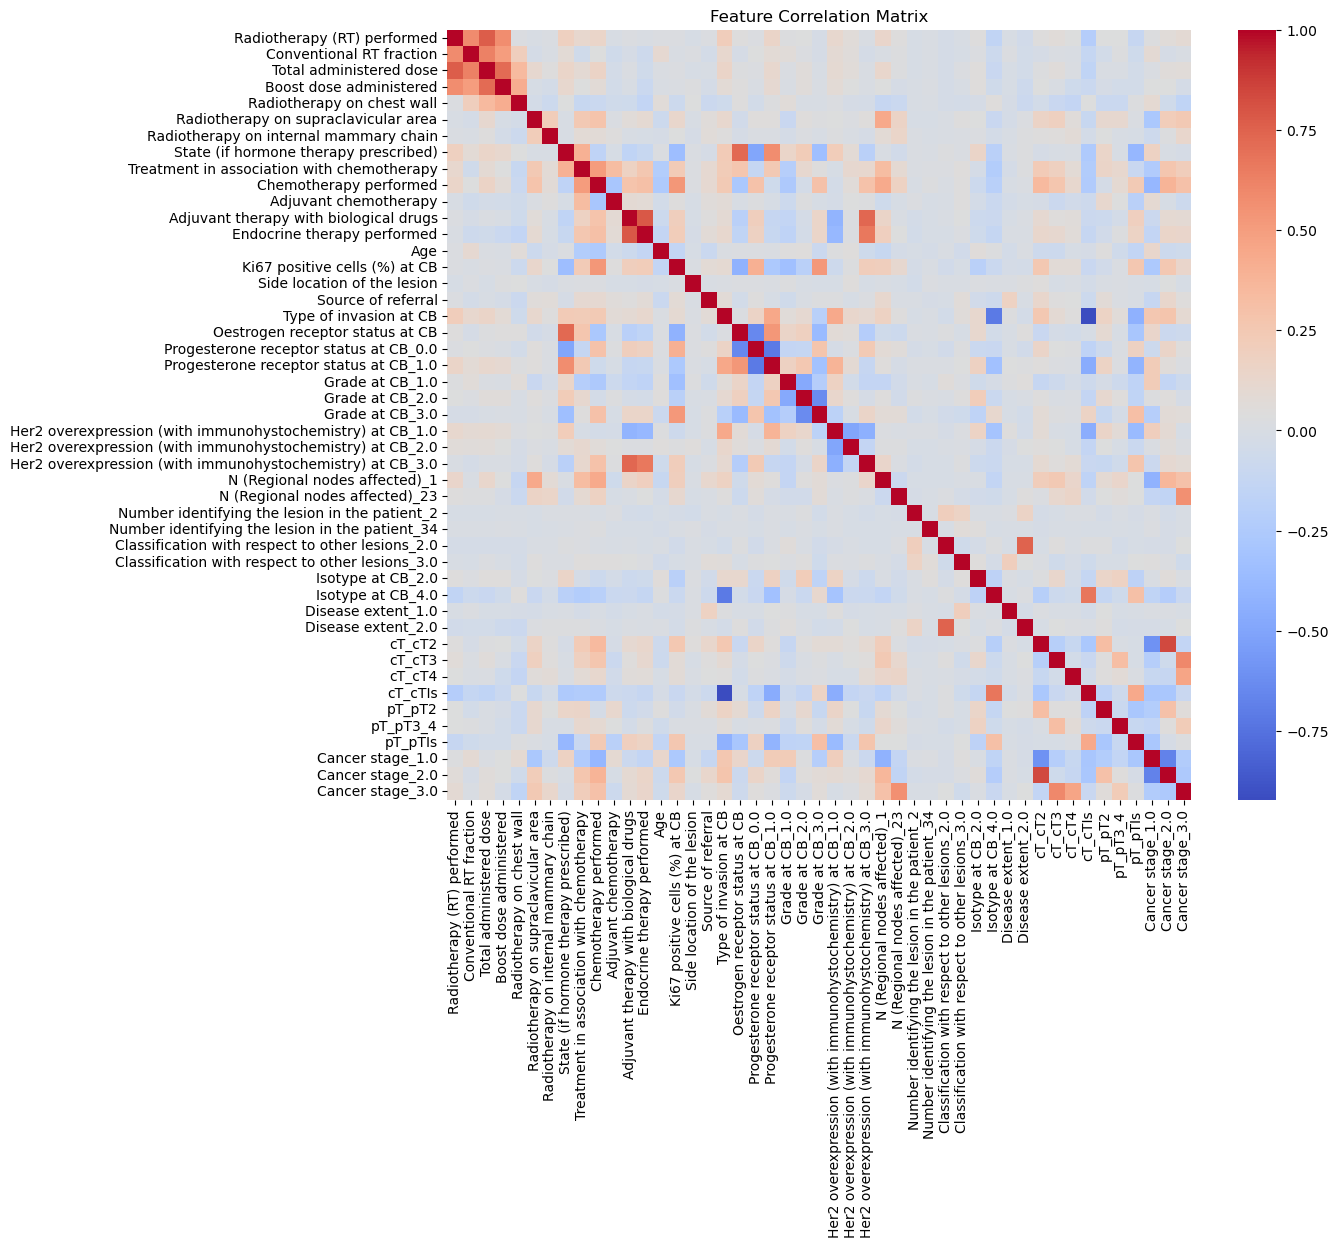

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# recomputed here for the heatmap (same as the cell above)
corr_matrix = data_x_scaled.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i) 
                       for i in range(len(df.columns))]
    return vif_data.sort_values(by="VIF", ascending=False)

print(calculate_vif(data_x_scaled))

                                              feature         VIF
17                             Type of invasion at CB  104.039942
20             Progesterone receptor status at CB_1.0   93.613398
24  Her2 overexpression (with immunohystochemistry...   80.748411
45                                   Cancer stage_2.0   66.407234
44                                   Cancer stage_1.0   58.395867
19             Progesterone receptor status at CB_0.0   32.356112
0                         Radiotherapy (RT) performed   24.371960
22                                    Grade at CB_2.0   24.282764
18                    Oestrogen receptor status at CB   20.614156
46                                   Cancer stage_3.0   18.929246
7               State (if hormone therapy prescribed)   18.094137
25  Her2 overexpression (with immunohystochemistry...   16.838325
26  Her2 overexpression (with immunohystochemistry...   14.651123
4                          Radiotherapy on chest wall   11.709491
37        

In [9]:
def reduce_vif(df, thresh=10.0):
    cols = df.columns.tolist()
    while True:
        vif = [variance_inflation_factor(df[cols].values, i) for i in range(len(cols))]
        max_vif = max(vif)
        if max_vif > thresh:
            max_idx = vif.index(max_vif)
            print(f"Dropping '{cols[max_idx]}' with VIF: {max_vif:.2f}")
            del cols[max_idx]
        else:
            break
    return df[cols]

data_x_reduced = reduce_vif(data_x_scaled)

Dropping 'Type of invasion at CB' with VIF: 104.04
Dropping 'Progesterone receptor status at CB_1.0' with VIF: 89.40
Dropping 'Cancer stage_2.0' with VIF: 40.46
Dropping 'Her2 overexpression (with immunohystochemistry) at CB_1.0' with VIF: 25.22
Dropping 'Oestrogen receptor status at CB' with VIF: 19.02
Dropping 'Radiotherapy (RT) performed' with VIF: 18.05
Dropping 'State (if hormone therapy prescribed)' with VIF: 12.65


In [11]:
def calculate_vif(df):
    vif_data = pd.DataFrame()
    vif_data["feature"] = df.columns
    vif_data["VIF"] = [variance_inflation_factor(df.values, i) 
                       for i in range(len(df.columns))]
    return vif_data.sort_values(by="VIF", ascending=False)

print(calculate_vif(data_x_reduced))

                                              feature       VIF
17                                    Grade at CB_2.0  9.765954
3                          Radiotherapy on chest wall  9.019124
38                                   Cancer stage_1.0  7.219007
7                              Chemotherapy performed  7.199529
31                                             cT_cT2  6.780987
39                                   Cancer stage_3.0  5.394867
18                                    Grade at CB_3.0  4.906539
6          Treatment in association with chemotherapy  4.808795
34                                            cT_cTIs  4.147177
32                                             cT_cT3  3.903069
9              Adjuvant therapy with biological drugs  3.901765
10                        Endocrine therapy performed  3.726418
16                                    Grade at CB_1.0  3.278805
20  Her2 overexpression (with immunohystochemistry...  2.933666
1                             Total admi